<a href="https://colab.research.google.com/github/jeffheaton/app_deep_learning/blob/main/t81_558_class_05_4_generators.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="In Colab öffnen"/></a>

# T81-558: Anwendungen tiefer neuronaler Netzwerke
**Modul 6: Convolutional Neural Networks (CNN) für Computer Vision**
* Dozent: [Jeff Heaton](https://sites.wustl.edu/jeffheaton/), McKelvey School of Engineering, [Jeff Heaton](https://sites.wustl.edu/jeffheaton/)
* Weitere Informationen finden Sie unter [class website](https://sites.wustl.edu/jeffheaton/t81-558/).

# Modul 5 Material

- Teil 5.1: Bildverarbeitung in Python [[Video]](https://www.youtube.com/watch?v=Sob7VDb4xh8&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN) [[Video]](https://www.youtube.com/watch?v=Sob7VDb4xh8&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN)
- Teil 5.2: Verwenden von Convolutional Neural Networks [[Video]](https://www.youtube.com/watch?v=jL0_lOpEwSk&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN) [[Video]](https://www.youtube.com/watch?v=jL0_lOpEwSk&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN)
- Teil 5.3: Vortrainierte neuronale Netzwerke verwenden[[Video]](https://www.youtube.com/watch?v=W2T-dfiHYSo&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN) [[Video]](https://www.youtube.com/watch?v=W2T-dfiHYSo&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN)
- **Teil 5.4: Generatoren und Bilderweiterung betrachten** [[Video]](https://www.youtube.com/watch?v=20JoEmQb810&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN) [[Video]](https://www.youtube.com/watch?v=20JoEmQb810&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN)
- Teil 5.5: Erkennen mehrerer Bilder mit YOLOv5 [[Video]](https://www.youtube.com/watch?v=7Uu1n9Tp0Mk&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN) [[Video]](https://www.youtube.com/watch?v=7Uu1n9Tp0Mk&list=PLjy4p-07OYzulelvJ5KVaT2pDlxivl_BN)

# Google CoLab-Anweisungen

Der folgende Code stellt sicher, dass Google CoLab die richtige Version von TensorFlow ausführt.

In [1]:
try:
    import google.colab

    COLAB = True
    print("Note: using Google CoLab")
except:
    print("Note: not using Google CoLab")
    COLAB = False

# Nutzen Sie eine GPU oder MPS (Apple), sofern verfügbar. (siehe Modul 3.2)
import torch

has_mps = torch.backends.mps.is_built()
device = "mps" if has_mps else "cuda" if torch.cuda.is_available() else "cpu"
print(f"Verwendetes Gerät: {device}")

Note: not using Google CoLab
Using device: mps


# Teil 5.4: Innere Augmentation

Die Klasse [ImageDataGenerator](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) bietet viele Optionen zur Bilderweiterung. Die Entscheidung, welche Erweiterungen verwendet werden sollen, kann sich auf die Effektivität Ihres Modells auswirken. In diesem Teil werden einige dieser Erweiterungen visualisiert, die Sie zum Trainieren Ihres neuronalen Netzwerks verwenden können. Wir beginnen mit dem Laden eines zu erweiternden Beispielbilds.

In [ ]:
import urllib.request
import shutil
from IPython.display import Image

URL = "https://data.heatonresearch.com/images/wustl/photos/landscape.jpg"

if COLAB:
    LOCAL_IMG_FILE = "/content/landscape.jpg"
else:
    # Anpassen an Ihr System
    LOCAL_IMG_FILE = "/Users/jeff/temp/landscape.jpg"

with urllib.request.urlopen(URL) as response, open(LOCAL_IMG_FILE, "wb") as out_file:
    shutil.copyfileobj(response, out_file)

Image(filename=LOCAL_IMG_FILE)

Als Nächstes stellen wir eine einfache Hilfsfunktion zur Visualisierung von vier von einem beliebigen Generator abgetasteten Bildern vor.

In [3]:
import torch
import torchvision.transforms as transforms
from torchvision.utils import make_grid
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt


def visualize_generator(img_file, transform):
    # Laden Sie das angeforderte Bild
    img = Image.open(img_file).resize((256, 256))

    # Transformationen auf das Bild anwenden
    imgs = [transform(img) for _ in range(4)]
    imgs = torch.stack(imgs)

    # Zeigen Sie die erweiterten Bilder in einem Rasterformat an
    grid = make_grid(imgs, nrow=2)

    # Zum Plotten in Numpy konvertieren
    grid_np = grid.numpy().transpose(1, 2, 0)
    grid_np = (grid_np * 255).astype(np.uint8)

    plt.figure(figsize=(15, 15))
    plt.axis("off")
    plt.imshow(grid_np)
    plt.show()

Wir beginnen mit dem Spiegeln des Bildes. Bei manchen Bildern ist das Spiegeln vielleicht nicht sinnvoll, wie zum Beispiel bei dieser Landschaft. Wenn Sie jedoch „Rauschen“ in Ihren Daten erwarten, wo einige Bilder gespiegelt sein könnten, dann kann diese Erweiterung nützlich sein, auch wenn sie der physikalischen Realität widerspricht.

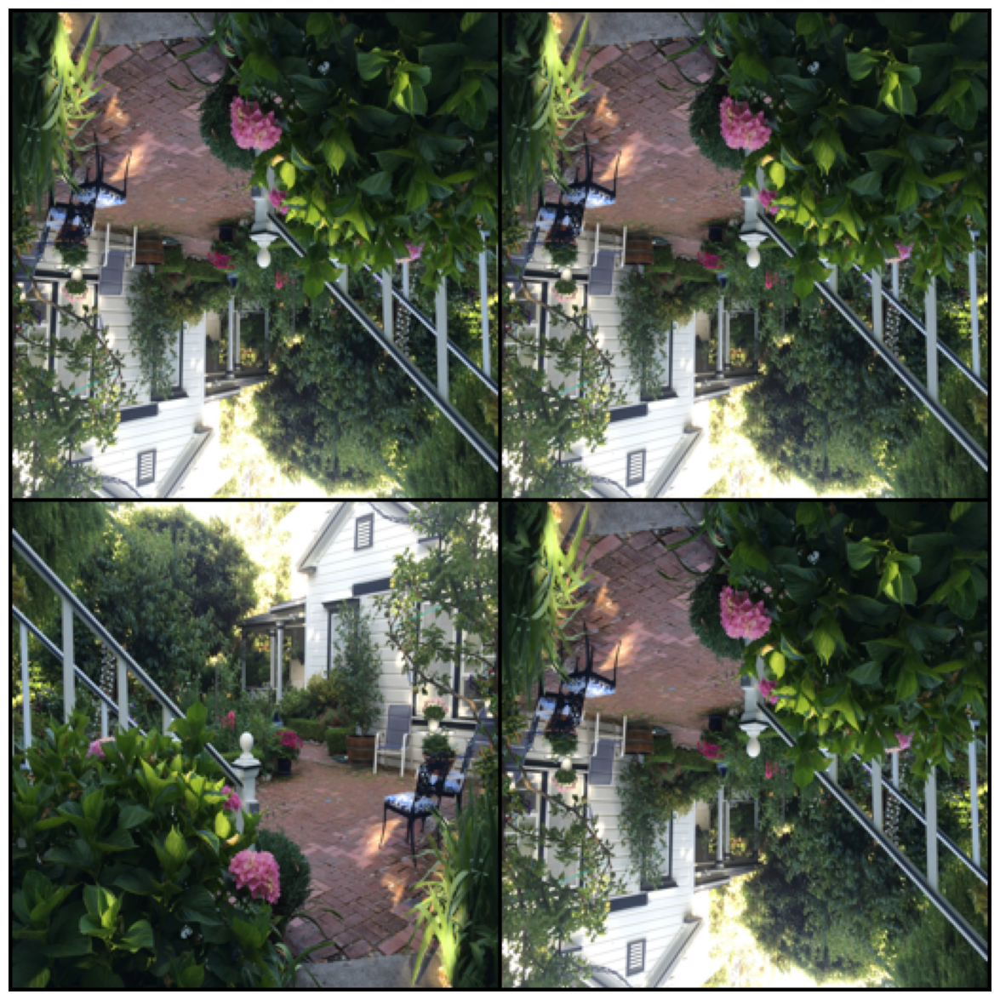

In [4]:
# Definieren Sie die Transformationen mit torchvision.transforms von PyTorch
transform = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.ToTensor(),
    ]
)

visualize_generator(LOCAL_IMG_FILE, transform)

Als Nächstes versuchen wir, das Bild zu verschieben. Merken Sie, dass ein Teil des Bildes fehlt? Es gibt verschiedene Möglichkeiten, die fehlenden Daten auszufüllen, die durch **padding_mode** gesteuert werden. In diesem Fall verwenden wir einfach das nächstgelegene Pixel zum Ausfüllen. Es ist auch möglich, Bilder zu drehen.

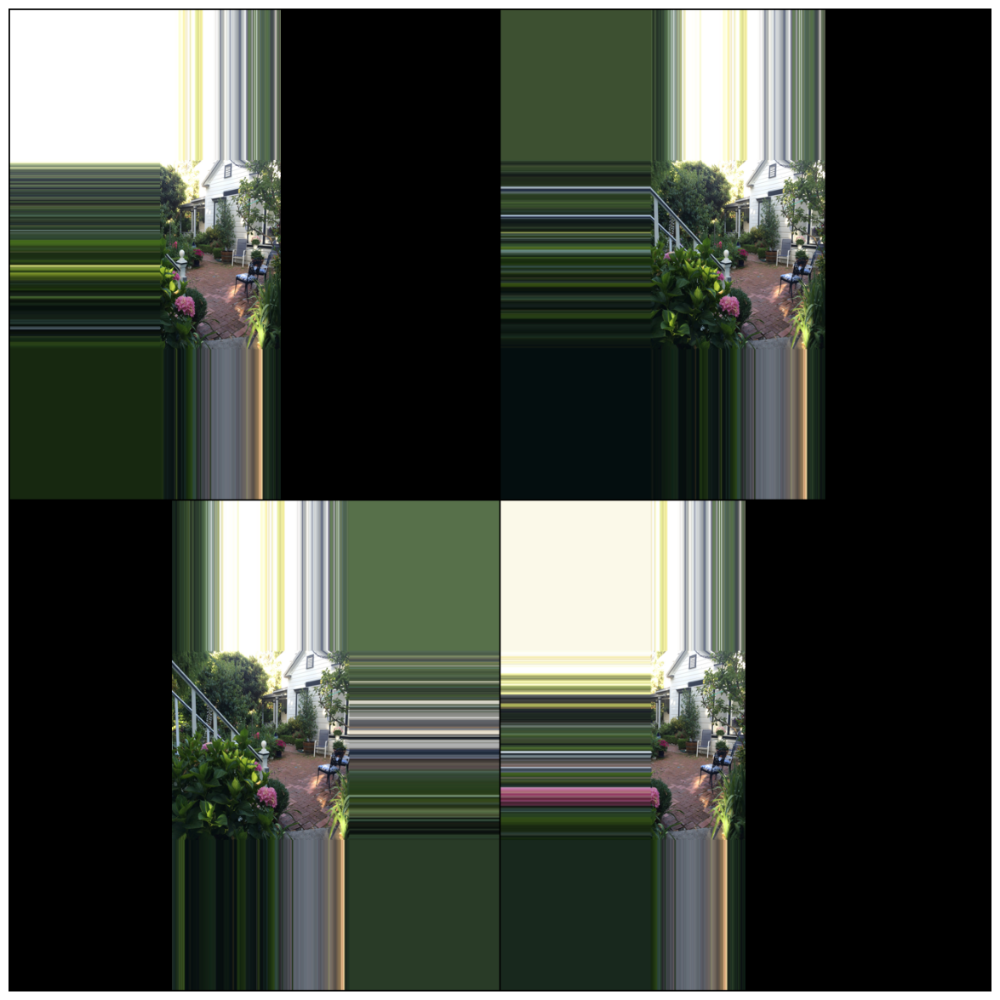

In [5]:
transform = transforms.Compose(
    [
        transforms.RandomAffine(
            degrees=0, translate=(0.5, 0)
        ),  # unter der Annahme einer Bildbreite von 400 bei einer Verschiebung von [-200,200]
        transforms.Pad(
            padding=200, fill=0, padding_mode="edge"
        ),  # mit dem nächsten Wert auffüllen
        transforms.ToTensor(),
    ]
)

visualize_generator(LOCAL_IMG_FILE, transform)

Wir können auch die Helligkeit anpassen.

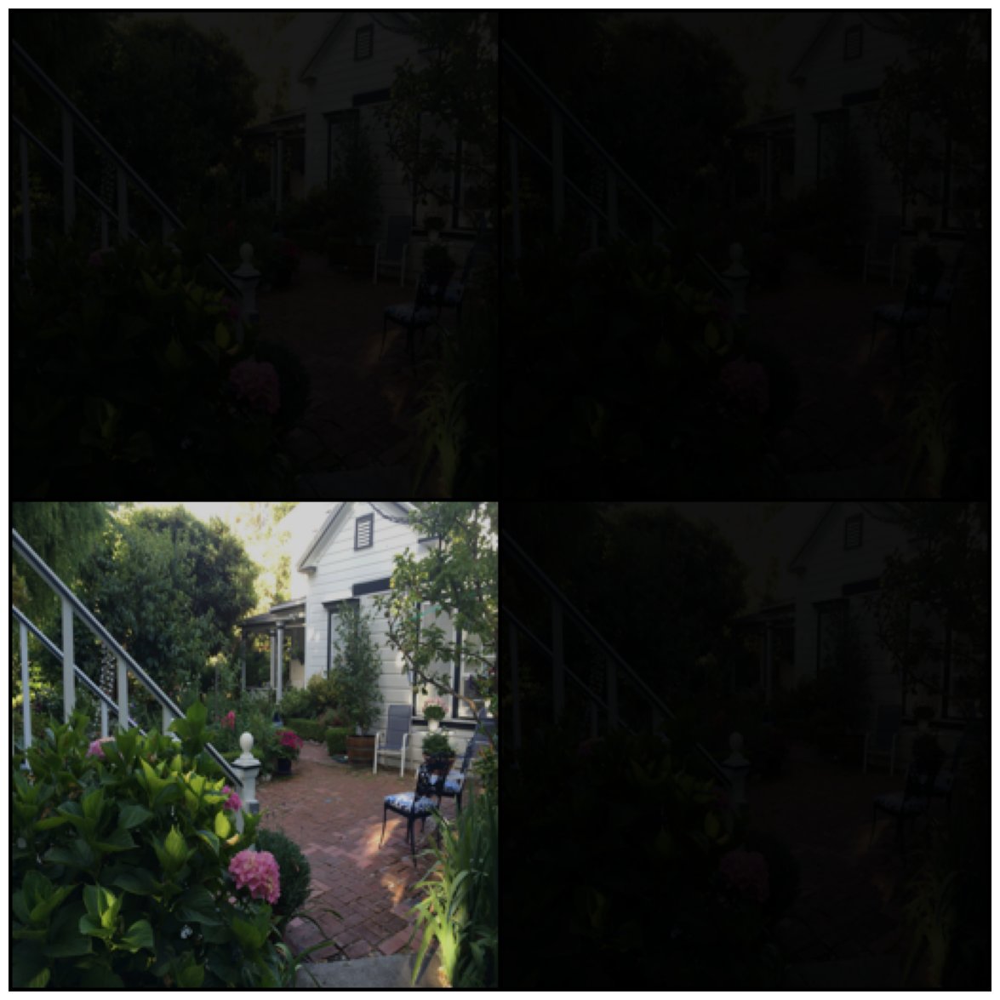

In [6]:
transform = transforms.Compose(
    [
        transforms.ColorJitter(
            brightness=(0, 1)
        ),  # Passen Sie die Helligkeit zwischen [0, 1] an
        transforms.ToTensor(),
    ]
)

visualize_generator(LOCAL_IMG_FILE, transform)

Das Scheren ist möglicherweise nicht für alle Bildtypen geeignet, da es das Bild streckt.

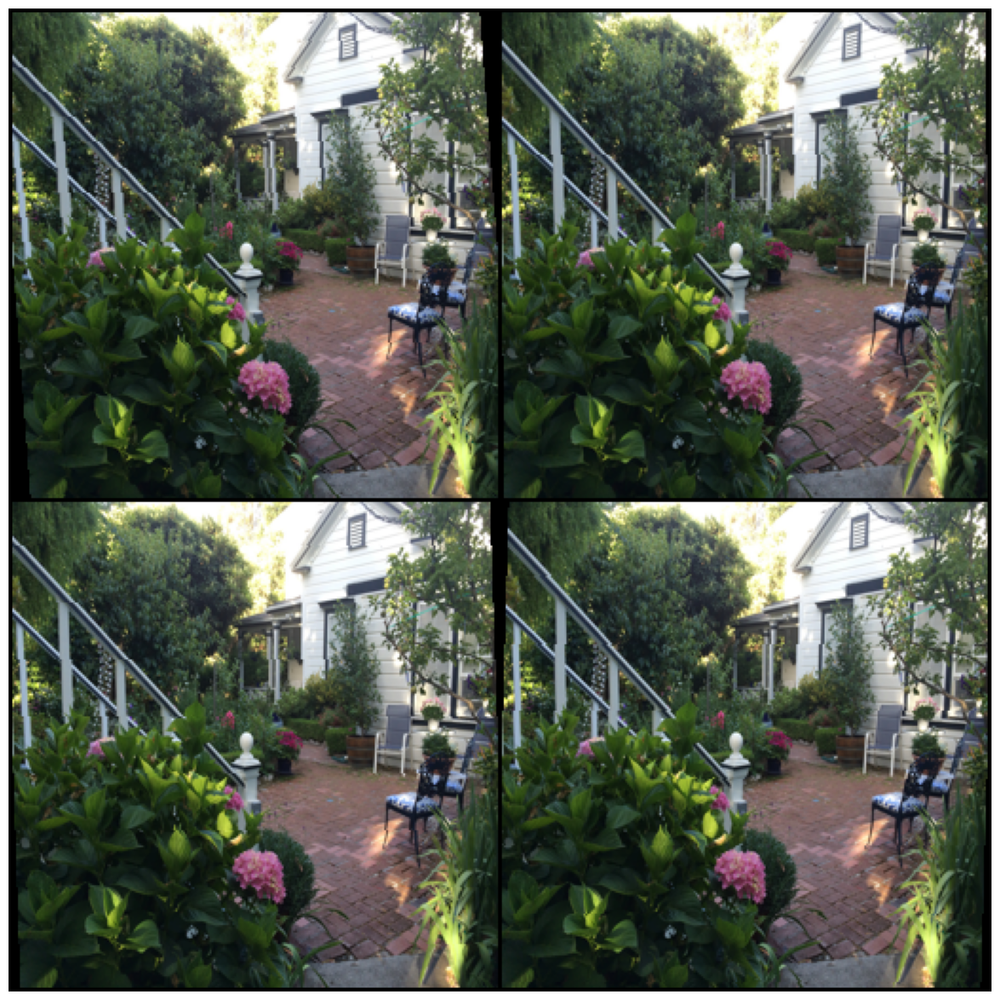

In [7]:
transform = transforms.Compose(
    [
        transforms.RandomAffine(degrees=0, shear=30),  # Schertransformation anwenden
        transforms.ToTensor(),
    ]
)

visualize_generator(LOCAL_IMG_FILE, transform)

Auch das Drehen von Bildern ist möglich.

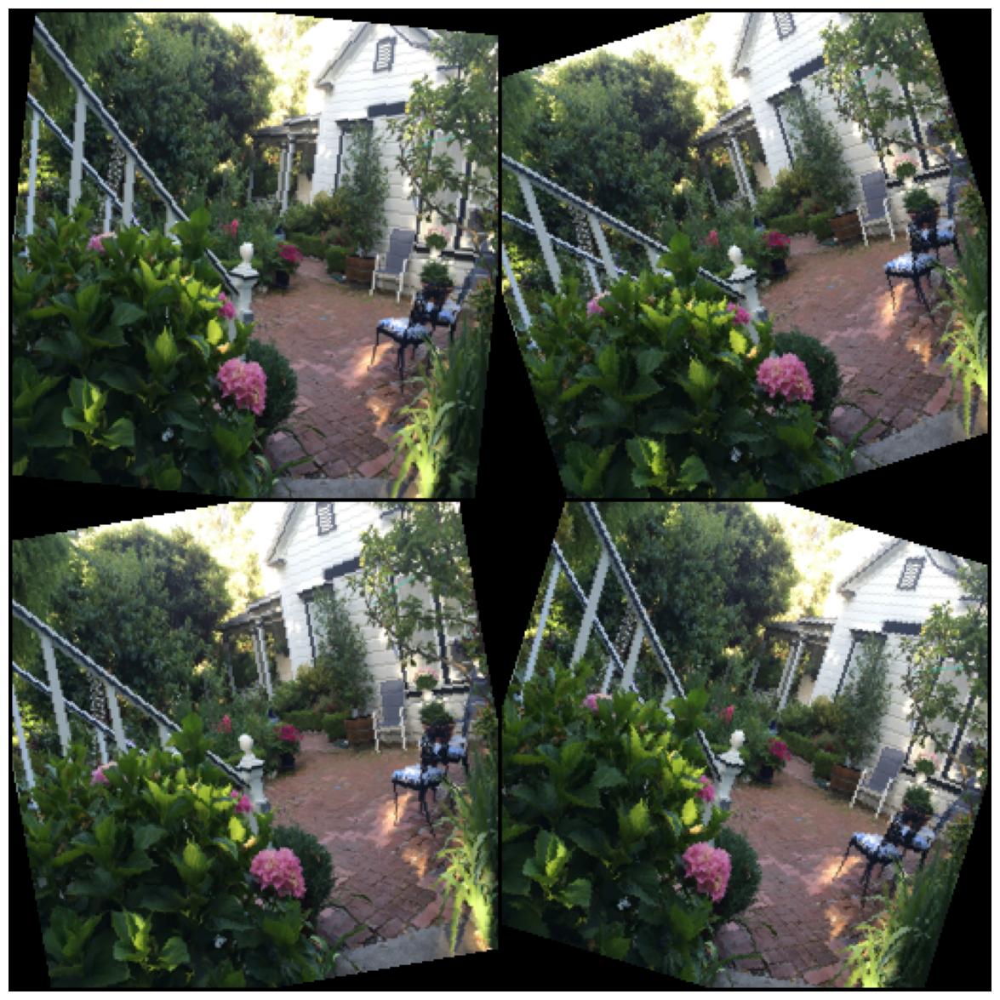

In [8]:
# Definieren Sie die Transformationen mit torchvision.transforms von PyTorch
transform = transforms.Compose(
    [
        transforms.RandomAffine(degrees=30),  # Drehen Sie das Bild um bis zu 30 Grad
        transforms.ToTensor(),
    ]
)

visualize_generator(LOCAL_IMG_FILE, transform)